# 望远镜法粒子鉴别模拟

> **单位约定**
> 
> 原始数据的射程是 **μm**、阻止本领是 **MeV/μm**，两者已经在同一长度标度下。
> 能量用 MeV、比能量用 MeV/u、厚度用 μm。

## 一、建立射程与能量损失计算
## 0. 环境与全局配置

In [1]:
# ========== Cell 0：运行环境（必须在 import ROOT 之前）==========
import os
from pathlib import Path
import re
import warnings

# 【必须】WSL 里的 DISPLAY 指向一个不存在的 X server（通常是 ":0"）。
# 只要 DISPLAY 有值，ROOT 就会走 X11 绘图路径，在 TPad::Paint /
# TCanvas::Update / TCanvas::SaveAs 里读坏内存并 segmentation violation。
# 移除它之后 ROOT 走无显示器的正常渲染路径，本 notebook 的所有画图都稳定。
os.environ.pop("DISPLAY", None)

import numpy as np
import ROOT
from IPython.display import display, Image

# 关掉 JSROOT 交互渲染，改用静态 PNG（可随 notebook 保存，稳定可靠）
get_ipython().run_line_magic("jsroot", "off")
ROOT.gStyle.SetOptStat(0)

In [2]:
# ========== Cell 1：自动发现数据目录、输出目录与绘图工具 ==========
# 支持从工作区根目录、notebook 项目目录或其父目录启动 kernel。
PROJECT_DIR_NAME = "Simulation of Isotopic Identification in a Three-layer Silicon Telescope"
_search_roots = [Path.cwd(), *Path.cwd().parents]
DATA_ROOT = None
for _base in _search_roots:
    for _candidate in (_base / "data", _base / PROJECT_DIR_NAME / "data"):
        if (_candidate / "element1-8").is_dir() and (_candidate / "helium").is_dir():
            DATA_ROOT = _candidate
            break
    if DATA_ROOT is not None:
        break

assert DATA_ROOT is not None, (
    "找不到同时包含 data/element1-8 和 data/helium 的目录；"
    "请确认 notebook 的 data 文件夹已放在项目目录中。"
)
DATA_DIR = str(DATA_ROOT / "helium")
ELEMENT_DATA_DIR = str(DATA_ROOT / "element1-8")
FIG_DIR = str(DATA_ROOT.parent / "figs")
os.makedirs(FIG_DIR, exist_ok=True)

# LISE++ 表格中 ATIMA 1.2 LS-theory 是第 3 组（0-based pair_idx=2）
PAIR_IDX = 2

# 三层 Si 望远镜厚度
T1, T2, T3 = 1000.0, 500.0, 1000.0   # μm

# 入射每核子能量扫描范围（要求 0 < eps <= 35 MeV/u）
EPS_MIN, EPS_MAX, N_EPS = 1.0, 35.0, 600

_fig_no = [0]


def show(canvas, name):
    """把 canvas 渲染成 PNG 并内嵌显示。"""
    canvas.Update()
    _fig_no[0] += 1
    fn = os.path.join(FIG_DIR, "fig%02d_%s.png" % (_fig_no[0], name))
    canvas.SaveAs(fn)
    display(Image(filename=fn))
    print("[OK] %s -> %s" % (name, fn))
    return canvas


def tgraph_xy(x, y):
    """由两个一维数组构造 TGraph，并保持 numpy 缓冲存活。"""
    x = np.ascontiguousarray(np.asarray(x, dtype=np.float64).ravel())
    y = np.ascontiguousarray(np.asarray(y, dtype=np.float64).ravel())
    g = ROOT.TGraph(len(x), x, y)
    g.__dict__["_keep"] = (x, y)
    return g


print("[OK] DATA_ROOT =", DATA_ROOT)
print("[OK] FIG_DIR   =", FIG_DIR)
print("[OK] 三层厚度 D1/D2/D3 = %g/%g/%g μm" % (T1, T2, T3))
print("[OK] ROOT", ROOT.gROOT.GetVersion())
print("[OK] DISPLAY =", os.environ.get("DISPLAY", "<unset>"))

[OK] DATA_ROOT = /home/xugeng/experimental-methods/Simulation of Isotopic Identification in a Three-layer Silicon Telescope/data
[OK] FIG_DIR   = /home/xugeng/experimental-methods/Simulation of Isotopic Identification in a Three-layer Silicon Telescope/figs
[OK] 三层厚度 D1/D2/D3 = 1000/500/1000 μm
[OK] ROOT 6.40.04
[OK] DISPLAY = <unset>


### 1. 读入数据

LISE++ 表格包含多组数据，解析时只取第 `pair_idx` 组，即ATIMA1.2LS数据。

In [3]:
# ========== Cell 2：LISE++ 数据表解析 ==========
def load_lise_data(filepath, pair_idx=PAIR_IDX):
    """返回 (N,2) 数组：[每核子能量(MeV/u), 表格数值]。"""
    filepath = Path(filepath)
    if not filepath.is_file():
        raise FileNotFoundError(f"LISE++ 数据文件不存在: {filepath}")

    data = []
    i_e, i_v = 2 * pair_idx, 2 * pair_idx + 1
    with filepath.open("r", encoding="utf-8", errors="replace") as f:
        for line in f:
            s = line.strip()
            if not s or s[0] in ("!", "#"):
                continue
            tok = s.split()
            if i_v >= len(tok):
                continue
            try:
                eps, value = float(tok[i_e]), float(tok[i_v])
            except ValueError:
                continue
            if np.isfinite(eps) and np.isfinite(value):
                data.append((eps, value))

    arr = np.asarray(data, dtype=float)
    if arr.ndim != 2 or arr.shape[0] < 2:
        raise ValueError(f"数据文件没有足够的有效数据点: {filepath}")
    arr = arr[np.argsort(arr[:, 0])]
    print("[INFO] %-26s -> %4d 点 (eps: %g ... %g MeV/u)"
          % (filepath.name, len(arr), arr[0, 0], arr[-1, 0]))
    return arr

In [4]:
# ========== Cell 3：读入 4,6,8He 的射程与能损 ==========
HE_ISOTOPES = [
    {"A": 4, "name": "4He", "color": ROOT.kBlue + 1,  "marker": 20},
    {"A": 6, "name": "6He", "color": ROOT.kRed + 1,   "marker": 21},
    {"A": 8, "name": "8He", "color": ROOT.kGreen + 2, "marker": 22},
]

print("========== 读入数据 ==========")
for iso in HE_ISOTOPES:
    iso["range"] = load_lise_data(os.path.join(DATA_DIR, iso["name"] + "RangeInSi.txt"))
    iso["dEdx"]  = load_lise_data(os.path.join(DATA_DIR, iso["name"] + "EnergyLossInSi.txt"))

print()
print("========== 数据诊断 ==========")
for iso in HE_ISOTOPES:
    r, s = iso["range"], iso["dEdx"]
    print("%4s: range %3d 点  R(eps=1)=%9.3f μm  R(eps=35)=%11.3f μm"
          % (iso["name"], len(r), np.interp(1.0, r[:, 0], r[:, 1]),
             np.interp(35.0, r[:, 0], r[:, 1])))
    print("      dEdx  %3d 点  S(eps=1)=%9.4f MeV/μm  S(eps=35)=%9.4f MeV/μm"
          % (len(s), np.interp(1.0, s[:, 0], s[:, 1]),
             np.interp(35.0, s[:, 0], s[:, 1])))

========== 读入数据 ==========
[INFO] 4HeRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 4HeEnergyLossInSi.txt      ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 6HeRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 6HeEnergyLossInSi.txt      ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 8HeRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 8HeEnergyLossInSi.txt      ->  268 点 (eps: 0.001 ... 50000 MeV/u)

========== 数据诊断 ==========
 4He: range 268 点  R(eps=1)=   17.423 μm  R(eps=35)=   6446.840 μm
      dEdx  268 点  S(eps=1)=   0.1664 MeV/μm  S(eps=35)=   0.0120 MeV/μm
 6He: range 268 点  R(eps=1)=   26.202 μm  R(eps=35)=   9695.280 μm
      dEdx  268 点  S(eps=1)=   0.1664 MeV/μm  S(eps=35)=   0.0120 MeV/μm
 8He: range 268 点  R(eps=1)=   34.976 μm  R(eps=35)=  12941.700 μm
      dEdx  268 点  S(eps=1)=   0.1664 MeV/μm  S(eps=35)=   0.0120 MeV/μm


## 2. ATIMA 1.2 LS 数据的阻止本领与射程闭环检查

将每核子阻止本领沿每核子能量积分可构造一个数值诊断量：

$$I_S(\varepsilon)=\int_0^{\varepsilon}S_N(\varepsilon')\,\mathrm{d}\varepsilon'$$

**注意：**这个积分不是粒子在材料中的累计能量沉积；其单位也不是 MeV。图中仅将它作为阻止本领曲线的数学诊断量展示，逐层真实能量沉积仍由 $R(E)$ 与 $E(R)$ 计算。

射程闭环检验使用：

$$R_N(\varepsilon)=\int_0^{\varepsilon}\frac{\mathrm{d}\varepsilon'}{S_N(\varepsilon')}$$

将该积分结果与 LISE++ 射程表比较，可检查射程表和阻止本领表是否一致。

In [5]:
# ========== Cell 4：阻止本领积分诊断与射程闭环 ==========
def integrated_stopping_power(dEdx, eps_max=EPS_MAX):
    """返回 I_S=∫S_N dε 的数学诊断曲线；它不是累计能量沉积。"""
    data = np.asarray(dEdx, dtype=float)
    data = data[data[:, 0] <= eps_max]
    eps, stopping = data[:, 0], data[:, 1]
    integral = np.concatenate(([0.0], np.cumsum(
        0.5 * (stopping[1:] + stopping[:-1]) * np.diff(eps)
    )))
    return eps, integral


def range_from_dEdx(dEdx, eps_query):
    """按 R_N(ε)=∫dε/S_N(ε) 积分，供射程表闭环检查。"""
    eps, stopping = np.asarray(dEdx, dtype=float).T
    dR = 0.5 * (1.0 / stopping[1:] + 1.0 / stopping[:-1]) * np.diff(eps)
    range_integral = np.concatenate(([0.0], np.cumsum(dR)))
    return float(np.interp(eps_query, eps, range_integral))


print("========== 阻止本领积分与射程闭环检查 ==========")
print("累计积分 I_S=∫S_N dε 仅作数学诊断，并非能量沉积；射程按 ∫dε/S_N 计算。")
for iso in HE_ISOTOPES:
    eps, int_s = integrated_stopping_power(iso["dEdx"], EPS_MAX)
    iso["intS_eps"], iso["intS"] = eps, int_s
    A = iso["A"]
    for e_q in (5.0, 10.0, 25.0):
        R_int_N = range_from_dEdx(iso["dEdx"], e_q)
        R_tab_N = float(np.interp(e_q, iso["range"][:, 0], iso["range"][:, 1])) / A
        print("%4s eps=%5.1f MeV/u : 积分射程=%8.2f vs 射程列/A=%8.2f (偏差=%+5.2f%%)"
              % (iso["name"], e_q, R_int_N, R_tab_N,
                 100.0 * (R_int_N - R_tab_N) / R_tab_N))
print("[NOTE] 逐层能损由 R(E) 与反函数 E(R) 计算。")

========== 阻止本领积分与射程闭环检查 ==========
累计积分 I_S=∫S_N dε 仅作数学诊断，并非能量沉积；射程按 ∫dε/S_N 计算。
 4He eps=  5.0 MeV/u : 积分射程=   53.22 vs 射程列/A=   53.27 (偏差=-0.09%)
 4He eps= 10.0 MeV/u : 积分射程=  174.13 vs 射程列/A=  174.23 (偏差=-0.06%)
 4He eps= 25.0 MeV/u : 积分射程=  877.57 vs 射程列/A=  877.96 (偏差=-0.04%)
 6He eps=  5.0 MeV/u : 积分射程=   53.22 vs 射程列/A=   53.41 (偏差=-0.36%)
 6He eps= 10.0 MeV/u : 积分射程=  174.12 vs 射程列/A=  174.68 (偏差=-0.32%)
 6He eps= 25.0 MeV/u : 积分射程=  877.55 vs 射程列/A=  880.23 (偏差=-0.30%)
 8He eps=  5.0 MeV/u : 积分射程=   53.22 vs 射程列/A=   53.47 (偏差=-0.48%)
 8He eps= 10.0 MeV/u : 积分射程=  174.12 vs 射程列/A=  174.88 (偏差=-0.44%)
 8He eps= 25.0 MeV/u : 积分射程=  877.54 vs 射程列/A=  881.23 (偏差=-0.42%)
[NOTE] 逐层能损由 R(E) 与反函数 E(R) 计算。


Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/Simulation of Isotopic Identification in a Three-layer Silicon Telescope/figs/fig01_Fig1a_stopping_integral_diagnostic.png has been created


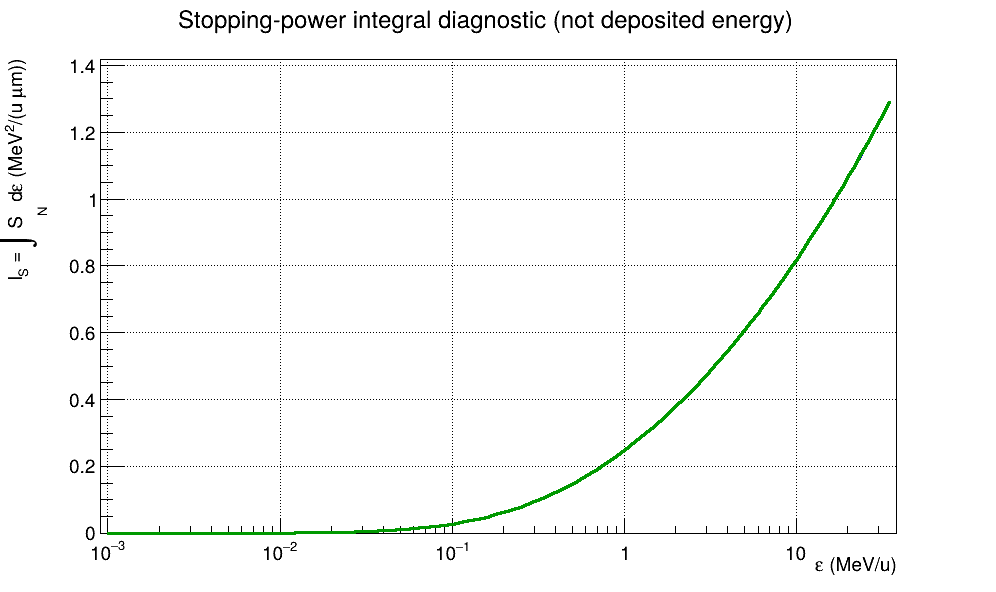

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/Simulation of Isotopic Identification in a Three-layer Silicon Telescope/figs/fig02_Fig1b_stopping_power.png has been created


[OK] Fig1a_stopping_integral_diagnostic -> /home/xugeng/experimental-methods/Simulation of Isotopic Identification in a Three-layer Silicon Telescope/figs/fig01_Fig1a_stopping_integral_diagnostic.png


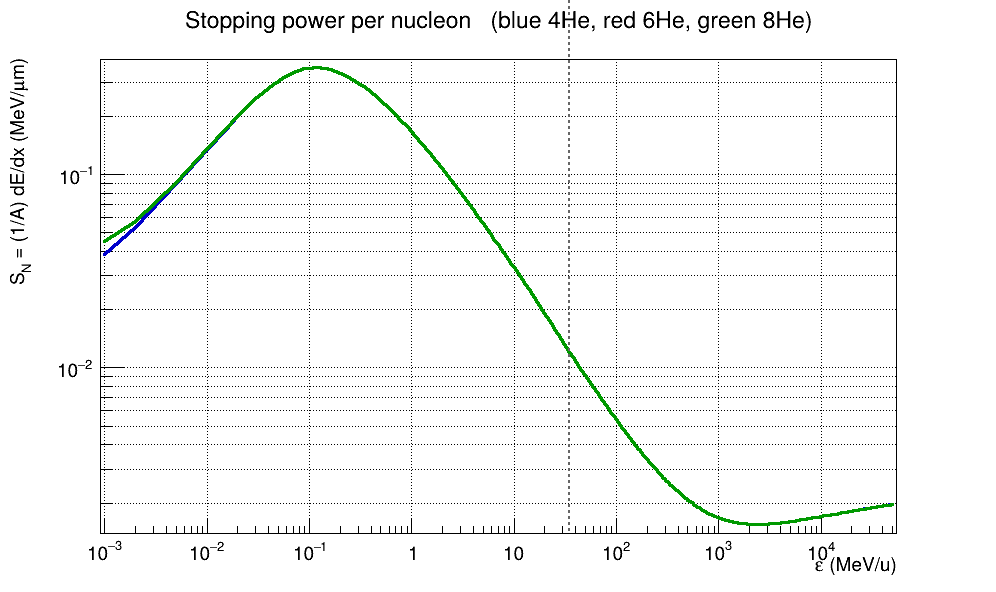

[OK] Fig1b_stopping_power -> /home/xugeng/experimental-methods/Simulation of Isotopic Identification in a Three-layer Silicon Telescope/figs/fig02_Fig1b_stopping_power.png
[OK] Fig.1 已生成


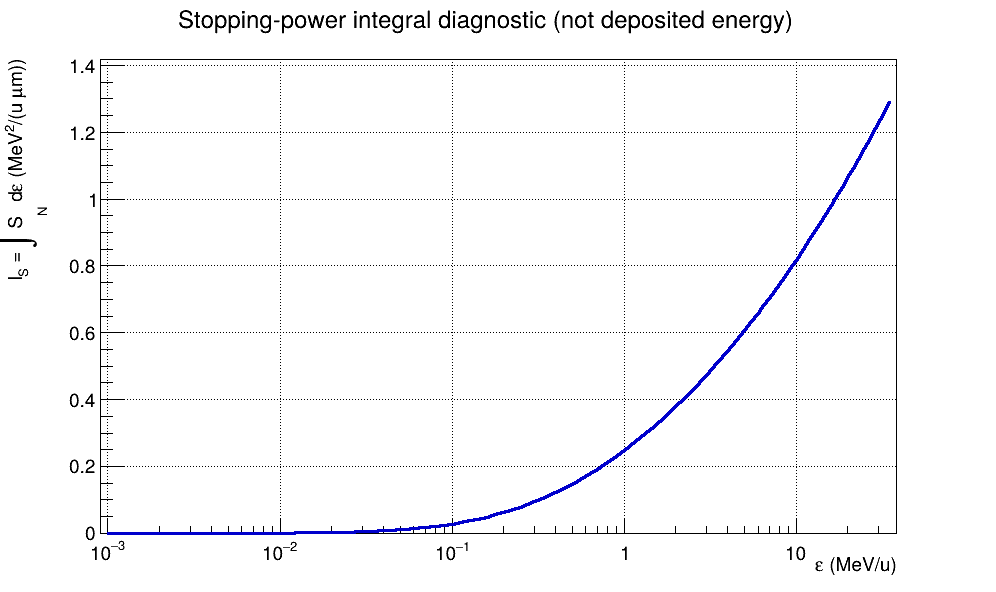

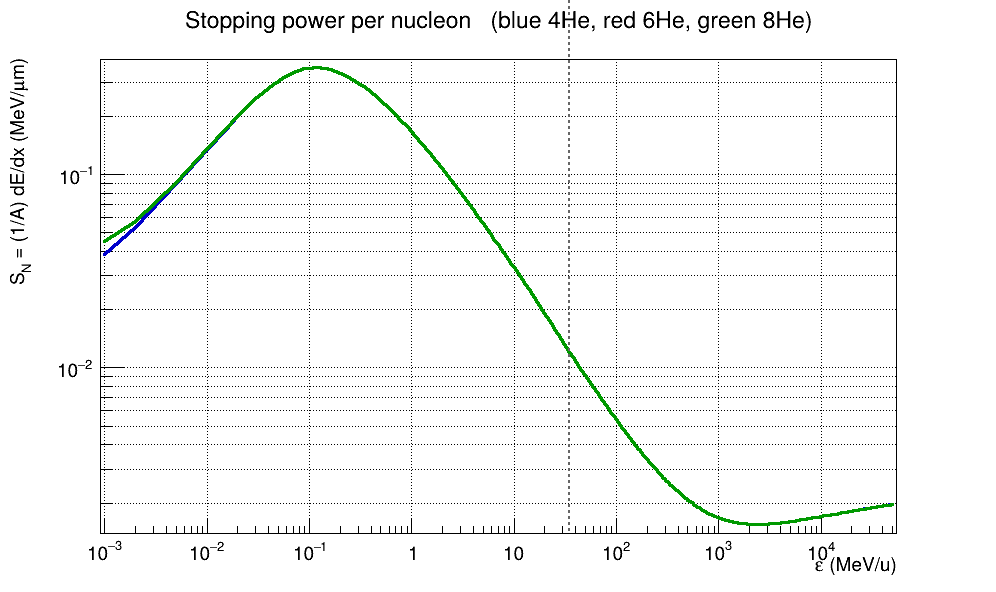

In [6]:
# ========== Cell 5：Fig.1a 阻止本领积分诊断 + Fig.1b 阻止本领 ==========
# 说明：I_S=∫S_N dε 仅为数学诊断量，不代表累计能量沉积。
h1 = None
c = ROOT.TCanvas("c_intS", "Stopping-power integral diagnostic", 1000, 620)
c.SetLogx()
c.SetGrid()
for iso in HE_ISOTOPES:
    g = tgraph_xy(iso["intS_eps"], iso["intS"])
    g.SetLineColor(iso["color"])
    g.SetLineWidth(3)
    if h1 is None:
        h1 = g
        g.SetTitle("Stopping-power integral diagnostic (not deposited energy);"
                   "#varepsilon (MeV/u);I_{S} = #int S_{N} d#varepsilon (MeV^{2}/(u #mum))")
        g.GetYaxis().SetTitleOffset(1.35)
    g.Draw("AL" if g is h1 else "L SAME")
show(c, "Fig1a_stopping_integral_diagnostic")

h2 = None
c = ROOT.TCanvas("c_sn", "Stopping power per nucleon", 1000, 620)
c.SetLogx()
c.SetLogy()
c.SetGrid()
for iso in HE_ISOTOPES:
    s = iso["dEdx"]
    g = tgraph_xy(s[:, 0], s[:, 1])
    g.SetLineColor(iso["color"])
    g.SetLineWidth(3)
    if h2 is None:
        h2 = g
        g.SetTitle("Stopping power per nucleon   (blue 4He, red 6He, green 8He);"
                   "#varepsilon (MeV/u);S_{N} = (1/A) dE/dx (MeV/#mum)")
        g.GetYaxis().SetTitleOffset(1.45)
        g.GetYaxis().SetLimits(1e-4, 1e1)
    g.Draw("AL" if g is h2 else "L SAME")
# 扫描窗口：用 frame 坐标画竖线（对数轴上用数据坐标会错位）
frame = c.GetFrame()
for e_win in (EPS_MIN, EPS_MAX):
    ln = ROOT.TLine(e_win, frame.GetY1(), e_win, frame.GetY2())
    ln.SetLineStyle(2)
    ln.SetLineColor(ROOT.kGray + 2)
    ln.SetLineWidth(2)
    ln.Draw()
show(c, "Fig1b_stopping_power")
print("[OK] Fig.1 已生成")

### 2.1 三种 He 同位素的同位素标度

用每核子能量 $\varepsilon=E/A$ 作横轴比较 4,6,8He：

- 相同 $\varepsilon$ 下阻止本领**接近**；
- 射程近似**与质量数成正比**：

$$R_{Z,A}(E)\approx\frac{A}{A_{\rm ref}}R_{Z,A_{\rm ref}}\left(E\frac{A_{\rm ref}}{A}\right)
\quad\Longleftrightarrow\quad
S_{Z,A}(E)\approx S_{Z,A_{\rm ref}}\left(E\frac{A_{\rm ref}}{A}\right)$$ 

下图左为 $S(\varepsilon)$，右为 $R(\varepsilon)$。右图同时画出
$R_{4\rm He}(\varepsilon)\times A/4$ 作为标度参考线（虚线）：若 ∝A 严格成立，
6He、8He 的实线应与对应虚线重合。

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/Simulation of Isotopic Identification in a Three-layer Silicon Telescope/figs/fig03_Fig2a_S_vs_eps.png has been created


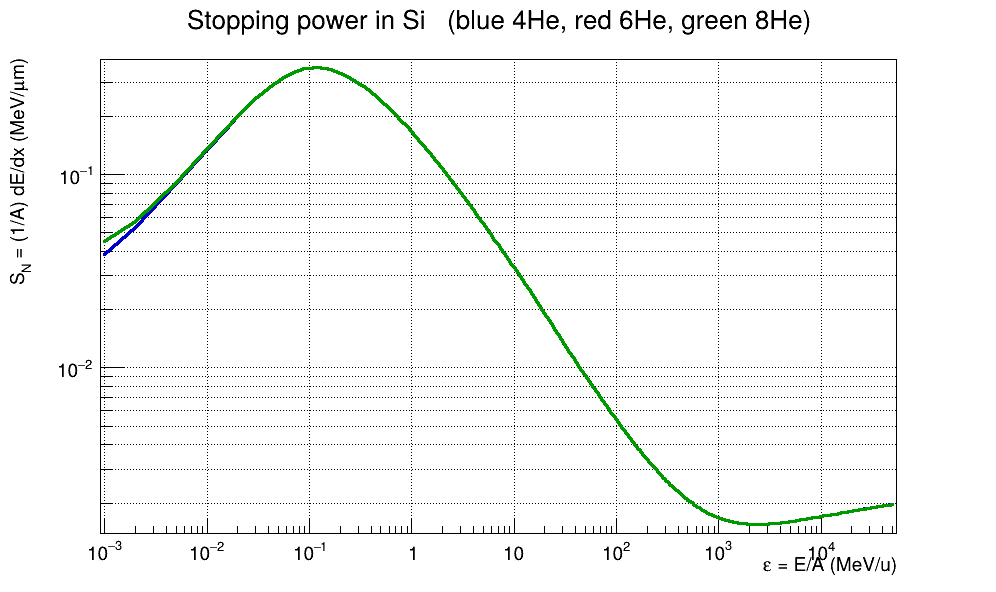

Info in <TCanvas::Print>: png file /home/xugeng/experimental-methods/Simulation of Isotopic Identification in a Three-layer Silicon Telescope/figs/fig04_Fig2b_RN_vs_eps.png has been created


[OK] Fig2a_S_vs_eps -> /home/xugeng/experimental-methods/Simulation of Isotopic Identification in a Three-layer Silicon Telescope/figs/fig03_Fig2a_S_vs_eps.png


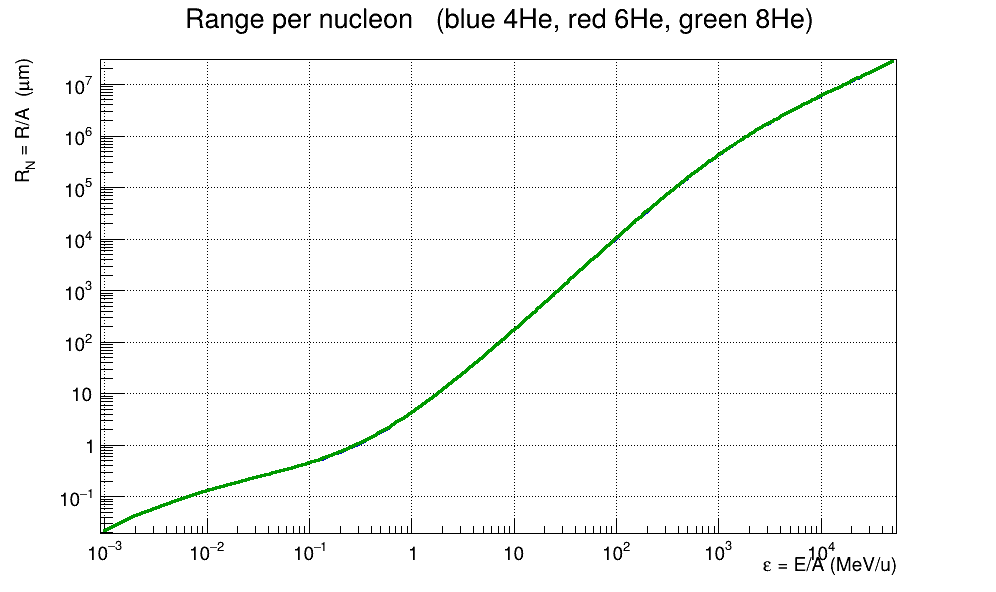

[OK] Fig2b_RN_vs_eps -> /home/xugeng/experimental-methods/Simulation of Isotopic Identification in a Three-layer Silicon Telescope/figs/fig04_Fig2b_RN_vs_eps.png

========== 同位素标度检验（每核子射程） ==========
相同 eps 下，各同位素的 R_N=R/A 与 4He 的偏差：
   4He: min= +0.00%  max= +0.00%  mean= +0.00%
   6He: min= +0.26%  max= +0.26%  mean= +0.26%
   8He: min= +0.37%  max= +0.37%  mean= +0.37%
[OK] Fig.2 已生成


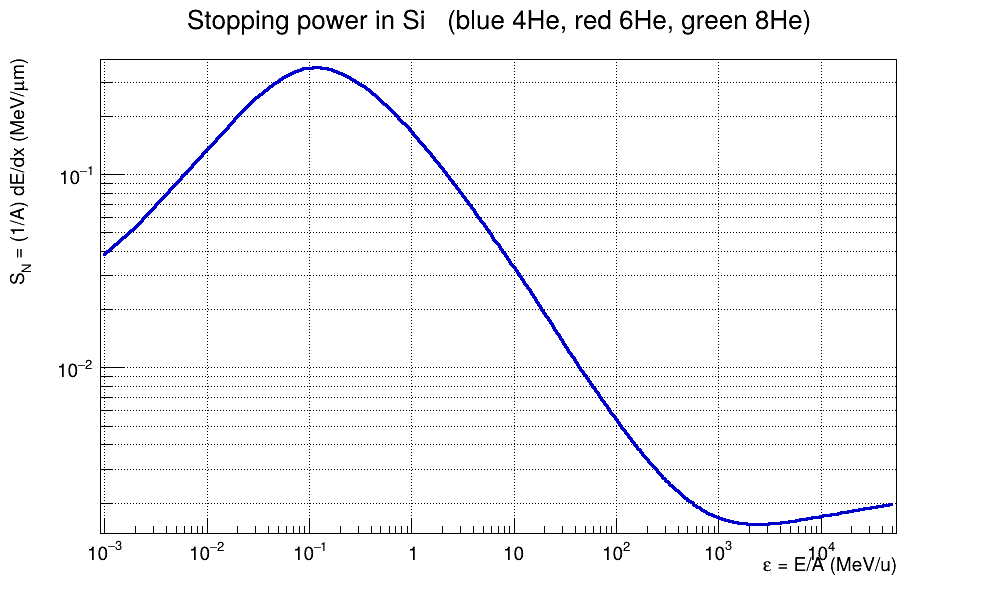

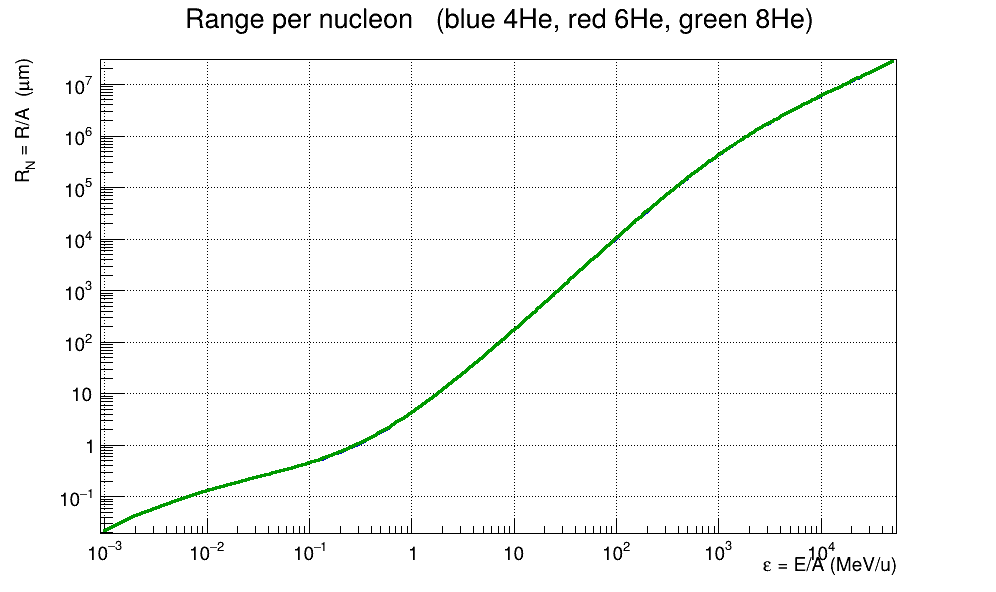

In [7]:
# ========== Cell 6：Fig.2 同位素标度检验（两个面板各一张图）==========
hS = None
c = ROOT.TCanvas("c_scale_s", "Stopping power vs eps", 1000, 620)
c.SetLogx()
c.SetLogy()
c.SetGrid()
for iso in HE_ISOTOPES:
    s = iso["dEdx"]
    g = tgraph_xy(s[:, 0], s[:, 1])
    g.SetLineColor(iso["color"])
    g.SetLineWidth(3)
    if hS is None:
        hS = g
        g.SetTitle("Stopping power in Si   (blue 4He, red 6He, green 8He);"
                   "#varepsilon = E/A (MeV/u);S_{N} = (1/A) dE/dx (MeV/#mum)")
        g.GetYaxis().SetTitleOffset(1.45)
    g.Draw("AL" if g is hS else "L SAME")
show(c, "Fig2a_S_vs_eps")

# 若 R ∝ A 成立，相同 eps 下 R_N=R/A 应与 A 无关。
hR = None
c = ROOT.TCanvas("c_scale_r", "Range per nucleon vs eps", 1000, 620)
c.SetLogx()
c.SetLogy()
c.SetGrid()
for iso in HE_ISOTOPES:
    r = iso["range"]
    range_per_nucleon = r[:, 1] / iso["A"]
    g = tgraph_xy(r[:, 0], range_per_nucleon)
    g.SetLineColor(iso["color"])
    g.SetLineWidth(3)
    if hR is None:
        hR = g
        g.SetTitle("Range per nucleon   (blue 4He, red 6He, green 8He);"
                   "#varepsilon = E/A (MeV/u);R_{N} = R/A  (#mum)")
        g.GetYaxis().SetTitleOffset(1.35)
    g.Draw("AL" if g is hR else "L SAME")
show(c, "Fig2b_RN_vs_eps")

print()
print("========== 同位素标度检验（每核子射程） ==========")
ref4 = HE_ISOTOPES[0]["range"]
mask = (ref4[:, 0] >= EPS_MIN) & (ref4[:, 0] <= EPS_MAX)
eps_cmp = ref4[mask, 0]
R4_N = ref4[mask, 1] / HE_ISOTOPES[0]["A"]
print("相同 eps 下，各同位素的 R_N=R/A 与 4He 的偏差：")
for iso in HE_ISOTOPES:
    r = iso["range"]
    R_iso_N = np.interp(eps_cmp, r[:, 0], r[:, 1] / iso["A"])
    dev = 100.0 * (R_iso_N - R4_N) / R4_N
    print("  %4s: min=%+6.2f%%  max=%+6.2f%%  mean=%+6.2f%%"
          % (iso["name"], dev.min(), dev.max(), dev.mean()))
print("[OK] Fig.2 已生成")

## 3. 建立射程-能量关系 R(E) 与反函数 E(R)

射程数据是离散的，在表格覆盖范围内对每核子能量作线性插值：

- 表格中的射程列为表格核素的完整射程 $R_{\\rm ref}$；使用参考核素时先换算为 $R_{N,\\rm ref}=R_{\\rm ref}/A_{\\rm ref}$；
- 对目标核素，若有自己的射程表则直接使用；缺表时按作业中的同位素标度关系估算：

$$R_{Z,A}(E)\\approx\\frac{A}{A_{\\rm ref}}R_{Z,A_{\\rm ref}}\\left(E\\frac{A_{\\rm ref}}{A}\\right),\\qquad E=A\\varepsilon.$$

该关系意味着目标总射程为 $A R_{N,\\rm ref}(\\varepsilon)$。超出表格能区的输入会报错，不进行静默外推。

单层能量沉积按下式计算：

$$R_{\\rm out}=\\max\\left[R(E_{\\rm in})-t,\\,0\\right],\\qquad E_{\\rm out}=E(R_{\\rm out}),\\qquad
\\Delta E=E_{\\rm in}-E_{\\rm out}$$

当 $R_{\\rm out}=0$ 时粒子已在层内停止，直接令 $E_{\\rm out}=0$、$\\Delta E=E_{\\rm in}$。

    # 题目缩放式：R_target(E)=A/A_ref*R_ref(E*A_ref/A)，其中 eps=E/A。

### 3.1 统一单层/多层仿真入口

后续通过核素注册表自动加载 Si 射程表。单层调用 `simulate_layer(E_in, Z, A, thickness)`，多层调用 `simulate_telescope(E_in, Z, A, layers)`，一次得到逐层沉积和剩余能量。`E_in` 为 MeV，可为标量或数组；厚度为 μm。缺少目标核素表时自动采用同元素最近质量数表，并在结果中记录参考质量数和数据来源，同时发出警告。

In [11]:
# ========== 射程-能量模型与统一仿真入口 ==========
# 表中射程是参考核素的总射程 R_ref(eps)；对目标质量数 A，按同位素标度
# R_target(E) = (A/A_ref) * R_ref(E/A) 计算。所有长度单位均为 μm。
_ELEMENT_Z = {"H": 1, "He": 2, "Li": 3, "Be": 4, "B": 5, "C": 6, "N": 7, "O": 8}
_RANGE_NAME_RE = re.compile(r"^(\d+)(He|Li|Be|B|C|N|O|H)RangeInSi\.txt$")
_RANGE_FILES = {}
for _range_dir in (Path(ELEMENT_DATA_DIR), Path(DATA_DIR)):
    for _range_path in sorted(_range_dir.glob("*RangeInSi.txt")):
        _match = _RANGE_NAME_RE.match(_range_path.name)
        if _match:
            _a = int(_match.group(1))
            _symbol = _match.group(2)
            _RANGE_FILES.setdefault((_ELEMENT_Z[_symbol], _a), _range_path)

if not _RANGE_FILES:
    raise FileNotFoundError("在 element1-8 和 helium 数据目录中没有找到 Si 射程表。")

TARGET_ISOTOPES = [
    {"Z": z, "A": a, "name": f"{a}{next(s for s, zz in _ELEMENT_Z.items() if zz == z)}",
     "range_file": str(path)}
    for (z, a), path in sorted(_RANGE_FILES.items())
]


def _as_output(value, scalar):
    """标量输入返回 Python 标量，数组输入保留 numpy 数组。"""
    array = np.asarray(value)
    return float(array) if scalar else array


def _check_thickness(thickness):
    """验证标量或可广播的层厚，单位 μm。"""
    thickness = np.asarray(thickness, dtype=float)
    if not np.all(np.isfinite(thickness)) or np.any(thickness < 0.0):
        raise ValueError("层厚必须是有限的非负数（μm）。")
    return float(thickness) if thickness.ndim == 0 else thickness


class RangeEnergy:
    """基于 LISE++ 射程表的 R(E)/E(R) 插值模型，支持缺表同位素缩放。"""

    def __init__(self, Z, A, range_data, A_ref=None, source=None):
        self.Z, self.A = int(Z), int(A)
        self.A_ref = self.A if A_ref is None else int(A_ref)
        self.source = None if source is None else str(source)
        if self.Z <= 0 or self.A <= 0 or self.A_ref <= 0:
            raise ValueError("Z、A 和 A_ref 必须为正整数。")
        data = np.asarray(range_data, dtype=float)
        if data.ndim != 2 or data.shape[1] != 2 or data.shape[0] < 2:
            raise ValueError("range_data 必须是至少含两个点的 (N, 2) 数组 [eps, R_ref]。")
        if not np.all(np.isfinite(data)):
            raise ValueError("射程表包含非有限数值。")
        data = data[np.argsort(data[:, 0])]
        if np.any(data[:, 0] <= 0.0) or np.any(np.diff(data[:, 0]) <= 0.0):
            raise ValueError("射程表每核子能量必须为正且严格递增。")
        if np.any(data[:, 1] <= 0.0) or np.any(np.diff(data[:, 1]) <= 0.0):
            raise ValueError("射程表射程必须为正且严格递增。")

        # 增加物理原点，保证 R(0)=0、E(0)=0 并可反插值到停止点附近。
        self.eps_tab = np.concatenate(([0.0], data[:, 0]))
        self.R_tab_N = np.concatenate(([0.0], data[:, 1] / self.A_ref))
        self.R_tab = self.R_tab_N * self.A_ref
        self.eps_max = float(self.eps_tab[-1])

    @staticmethod
    def _scalar_input(value):
        array = np.asarray(value, dtype=float)
        if not np.all(np.isfinite(array)):
            raise ValueError("输入必须全部为有限数值。")
        return array, array.ndim == 0

    def R_of_eps(self, eps):
        """由每核子能量（MeV/u）得到目标核素总射程（μm）。"""
        eps, scalar = self._scalar_input(eps)
        if np.any(eps < 0.0) or np.any(eps > self.eps_max):
            raise ValueError(f"eps 超出射程表范围 [0, {self.eps_max:g}] MeV/u。")
        r_per_ref_nucleon = np.interp(eps, self.eps_tab, self.R_tab_N)
        return _as_output(self.A * r_per_ref_nucleon, scalar)

    def R_of_E(self, energy):
        """由总能量（MeV）得到目标核素总射程（μm）。"""
        energy, scalar = self._scalar_input(energy)
        if np.any(energy < 0.0):
            raise ValueError("总能量不能为负数。")
        result = self.R_of_eps(energy / self.A)
        return _as_output(result, scalar)

    def E_of_R(self, distance):
        """由目标核素剩余射程（μm）反插值总能量（MeV）。"""
        distance, scalar = self._scalar_input(distance)
        max_range = self.A * self.R_tab_N[-1]
        if np.any(distance < 0.0) or np.any(distance > max_range):
            raise ValueError(f"射程超出 [0, {max_range:g}] μm；不进行外推。")
        eps = np.interp(distance / self.A, self.R_tab_N, self.eps_tab)
        return _as_output(self.A * eps, scalar)

    def range_after(self, energy, thickness):
        """穿过 thickness（μm）后的剩余射程；停止粒子的剩余射程为 0。"""
        thickness = _check_thickness(thickness)
        return np.maximum(np.asarray(self.R_of_E(energy)) - thickness, 0.0)

    def deposit(self, energy, thickness):
        """返回 (沉积能量, 出射能量)，能量和层厚支持可广播数组。"""
        energy, energy_scalar = self._scalar_input(energy)
        if np.any(energy < 0.0):
            raise ValueError("总能量不能为负数。")
        thickness = _check_thickness(thickness)
        scalar = energy_scalar and np.asarray(thickness).ndim == 0
        range_in = np.asarray(self.R_of_E(energy), dtype=float)
        range_out = np.maximum(range_in - thickness, 0.0)
        energy_out = np.asarray(self.E_of_R(range_out), dtype=float)
        deposited = np.maximum(energy - energy_out, 0.0)
        return _as_output(deposited, scalar), _as_output(energy_out, scalar)


_RANGE_ENERGY_CACHE = {}


def get_range_energy(Z, A):
    """取用精确核素射程表；缺表时采用同元素质量数最近的表并警告。"""
    Z, A = int(Z), int(A)
    key = (Z, A)
    if key in _RANGE_ENERGY_CACHE:
        return _RANGE_ENERGY_CACHE[key]
    if Z not in _ELEMENT_Z.values() or A <= 0:
        raise ValueError(f"无效核素 Z={Z}, A={A}。")
    source_key = key
    if source_key not in _RANGE_FILES:
        same_element = [(z, a) for z, a in _RANGE_FILES if z == Z]
        if not same_element:
            raise FileNotFoundError(f"没有 Z={Z} 的 Si 射程表，无法进行同位素缩放。")
        source_key = min(same_element, key=lambda item: (abs(item[1] - A), item[1]))
        warnings.warn(
            f"缺少 Z={Z}, A={A} 射程表；改用 A_ref={source_key[1]} 的同元素表进行质量数缩放。",
            RuntimeWarning,
            stacklevel=2,
        )
    source_path = _RANGE_FILES[source_key]
    source_data = load_lise_data(source_path)
    model = RangeEnergy(Z, A, source_data, A_ref=source_key[1], source=source_path)
    _RANGE_ENERGY_CACHE[key] = model
    return model


def _range_metadata(Z, A):
    model = get_range_energy(Z, A)
    return {
        "Z": int(Z), "A": int(A), "A_ref": model.A_ref,
        "range_file": model.source, "scaled": model.A != model.A_ref,
    }


def simulate_layer(E_in, Z, A, thickness):
    """模拟单层 Si：返回入射/出射能量、沉积能量及射程来源信息。"""
    model = get_range_energy(Z, A)
    dE, E_out = model.deposit(E_in, thickness)
    metadata = _range_metadata(Z, A)
    metadata.update({
        "E_in": E_in,
        "E_out": E_out,
        "dE": dE,
        "R_in": model.R_of_E(E_in),
        "R_out": model.range_after(E_in, thickness),
        "thickness": _check_thickness(thickness),
    })
    return metadata


def simulate_telescope(E_in, Z, A, layers):
    """按顺序模拟多层 Si，返回每层沉积/出射能量及实际停止层。"""
    layer_thicknesses = tuple(_check_thickness(t) for t in layers)
    if not layer_thicknesses:
        raise ValueError("layers 至少需要包含一层厚度。")
    model = get_range_energy(Z, A)
    energy_in, scalar = model._scalar_input(E_in)
    if np.any(energy_in < 0.0):
        raise ValueError("总能量不能为负数。")

    result = _range_metadata(Z, A)
    result["E_in"] = _as_output(energy_in, scalar)
    remaining = energy_in.copy()
    stop = np.zeros(energy_in.shape, dtype=np.int64)
    for index, thickness in enumerate(layer_thicknesses, start=1):
        dE, energy_out = model.deposit(remaining, thickness)
        dE_array = np.asarray(dE, dtype=float)
        out_array = np.asarray(energy_out, dtype=float)
        result[f"dE{index}"] = _as_output(dE_array, scalar)
        result[f"E{index}"] = _as_output(out_array, scalar)
        newly_stopped = (out_array == 0.0) & (stop == 0)
        stop[newly_stopped] = index
        remaining = out_array

    result["E_out"] = _as_output(remaining, scalar)
    result["R_out"] = model.R_of_E(remaining)
    result["dE"] = _as_output(energy_in - remaining, scalar)
    result["stop"] = int(stop) if scalar else stop
    result["layers"] = layer_thicknesses
    return result


def simulate_isotope_scan(isotopes=None, eps_grid=None, layers=None):
    """对核素列表扫描每核子能量，逐核素调用三层仿真并返回结果字典列表。"""
    isotopes = TARGET_ISOTOPES if isotopes is None else isotopes
    eps_grid = EPS_GRID if eps_grid is None else eps_grid
    layers = (T1, T2, T3) if layers is None else layers
    eps_grid = np.asarray(eps_grid, dtype=float)
    if eps_grid.ndim != 1 or eps_grid.size == 0 or not np.all(np.isfinite(eps_grid)):
        raise ValueError("eps_grid 必须是非空的一维有限数值数组。")
    if np.any(eps_grid < 0.0):
        raise ValueError("eps_grid 中的每核子能量不能为负数。")

    results = []
    for isotope in isotopes:
        Z, A = int(isotope["Z"]), int(isotope["A"])
        item = simulate_telescope(A * eps_grid, Z=Z, A=A, layers=layers)
        item["eps"] = eps_grid.copy()
        item["name"] = isotope.get("name", f"Z{Z}A{A}")
        results.append(item)
    return results


print("[OK] RangeEnergy 与统一仿真函数已定义；发现 %d 个可扫描核素。" % len(TARGET_ISOTOPES))

[OK] RangeEnergy 与统一仿真函数已定义；发现 30 个可扫描核素。


In [14]:
# 4,6,8He 专用模型注册表，供射程闭环检查与穿透点分析复用。
RE = {iso["name"]: get_range_energy(2, iso["A"]) for iso in HE_ISOTOPES}
print("[OK] RE 已准备：", ", ".join(RE))

[OK] RE 已准备： 4He, 6He, 8He


In [ ]:
# 标量接口回归检查：保证 notebook 示例、用户单次输入和数组扫描一致。
_scalar_layer = simulate_layer(10.0, Z=6, A=12, thickness=500.0)
_scalar_tel = simulate_telescope(10.0, Z=6, A=12, layers=(T1, T2, T3))
assert np.isclose(_scalar_layer["dE"] + _scalar_layer["E_out"], 10.0)
assert np.isclose(_scalar_tel["dE1"] + _scalar_tel["dE2"] + _scalar_tel["dE3"] + _scalar_tel["E3"], 10.0)
assert _scalar_tel["stop"] == 1
_vector_layer = simulate_layer(np.array([10.0, 100.0]), Z=6, A=12, thickness=500.0)
assert _vector_layer["dE"].shape == (2,) and _vector_layer["E_out"].shape == (2,)
print("[OK] 单层/多层标量与数组接口检查通过。")

In [12]:
# 示例：以 12C 在 500 μm Si 中的单层沉积演示统一入口。
example_layer = simulate_layer(np.array([10.0, 100.0]), Z=6, A=12, thickness=500.0)
print("12C 单层结果：dE =", example_layer["dE"], "MeV; E_out =", example_layer["E_out"], "MeV")

# 预检全部目标核素的表格解析、R(E)->E(R)闭环及三层调用。
# 该网格只用于轻量功能检查；正式扫描使用后面的 EPS_GRID。
_preflight_eps = np.array([1.0, 10.0, 35.0])
_preflight = simulate_isotope_scan(eps_grid=_preflight_eps)
assert len(_preflight) == len(TARGET_ISOTOPES)
for _item in _preflight:
    _model = get_range_energy(_item["Z"], _item["A"])
    _energy = _preflight_eps * _item["A"]
    _energy_check = _model.E_of_R(_model.R_of_E(_energy))
    assert np.allclose(_energy_check, _energy, rtol=1e-10, atol=1e-10)
    assert float(_model.E_of_R(0.0)) == 0.0
    _dE_zero, _E_zero = _model.deposit(_energy, 0.0)
    assert np.allclose(_dE_zero, 0.0) and np.allclose(_E_zero, _energy)
    _dE_stop, _E_stop = _model.deposit(_energy, _model.R_of_E(_energy) + 1.0)
    assert np.allclose(_dE_stop, _energy) and np.allclose(_E_stop, 0.0)
    assert np.all(_item["dE1"] >= 0.0) and np.all(_item["dE2"] >= 0.0) and np.all(_item["dE3"] >= 0.0)
    assert np.allclose(_item["dE1"] + _item["dE2"] + _item["dE3"] + _item["E3"], _energy)

# 用 12C 数据模拟缺少的 14C 表，直接检验题目给出的同位素缩放关系。
_c12_model = get_range_energy(6, 12)
_c12_total_range = np.column_stack((_c12_model.eps_tab[1:], _c12_model.R_tab_N[1:] * _c12_model.A_ref))
_c14_from_c12 = RangeEnergy(6, 14, _c12_total_range, A_ref=12)
_test_eps = np.array([5.0, 10.0, 20.0])
_expected_R14 = (14.0 / 12.0) * _c12_model.R_of_eps(_test_eps)
assert np.allclose(_c14_from_c12.R_of_E(14.0 * _test_eps), _expected_R14)
print("[OK] 全部 %d 个目标核素及参考同位素缩放通过预检。" % len(_preflight))

[INFO] 12CRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
12C 单层结果：dE = [ 10. 100.] MeV; E_out = [0. 0.] MeV
[INFO] 1HRangeInSi.txt            ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 2HRangeInSi.txt            ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 3HRangeInSi.txt            ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 3HeRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 4HeRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 6HeRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 8HeRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 6LiRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 7LiRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 8LiRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 9LiRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)
[INFO] 7BeRangeInSi.txt           ->  268 点 (eps: 0.001 ... 50000 MeV/u)


### 3.2 射程清单

列出 10、100、200 MeV 的 4He、12C、16O 在 Si 中的射程。

In [15]:
# ========== Cell 8：10/100/200 MeV 的 4He、12C、16O 射程清单 ==========
print("========== 射程清单（Si） ==========")
print("%6s %10s %13s %14s" % ("核素", "E (MeV)", "E/A (MeV/u)", "R (μm)"))
for Z, A, name in ((2, 4, "4He"), (6, 12, "12C"), (8, 16, "16O")):
    obj = get_range_energy(Z, A)
    for E in (10.0, 100.0, 200.0):
        print("%6s %10.1f %13.3f %14.2f" % (name, E, E / A, float(obj.R_of_E(E))))

print()
print("========== 反函数闭环检查 R -> E -> R ==========")
for name, obj in RE.items():
    for eps0 in (5.0, 15.0, 30.0):
        E = obj.A * eps0
        R = float(obj.R_of_E(E))
        E_back = float(obj.E_of_R(R))
        print("%4s: eps=%5.1f -> R=%10.2f μm -> eps_back=%7.4f MeV/u (相对偏差 %+.2e %%)"
              % (name, eps0, R, E_back / obj.A, 100.0 * (E_back - E) / E))

========== 射程清单（Si） ==========
    核素    E (MeV)   E/A (MeV/u)         R (μm)
   4He       10.0         2.500          68.43
   4He      100.0        25.000        3511.83
   4He      200.0        50.000       12243.30
   12C       10.0         0.833           9.14
   12C      100.0         8.333         186.13
   12C      200.0        16.667         587.53
   16O       10.0         0.625           6.72
   16O      100.0         6.250          96.32
   16O      200.0        12.500         281.65

========== 反函数闭环检查 R -> E -> R ==========
 4He: eps=  5.0 -> R=    213.09 μm -> eps_back= 5.0000 MeV/u (相对偏差 +0.00e+00 %)
 4He: eps= 15.0 -> R=   1415.11 μm -> eps_back=15.0000 MeV/u (相对偏差 +0.00e+00 %)
 4He: eps= 30.0 -> R=   4883.40 μm -> eps_back=30.0000 MeV/u (相对偏差 +0.00e+00 %)
 6He: eps=  5.0 -> R=    320.46 μm -> eps_back= 5.0000 MeV/u (相对偏差 +0.00e+00 %)
 6He: eps= 15.0 -> R=   2128.16 μm -> eps_back=15.0000 MeV/u (相对偏差 +0.00e+00 %)
 6He: eps= 30.0 -> R=   7344.05 μm -> eps_back=30.0000 M

## 4. 三层 Si 望远镜仿真（实验设置 1000 / 500 / 1000 μm）

逐层递推：

$$\Delta E_1=\mathrm{deposit}(E,\,1000),\quad E_1=\mathrm{out}(E,\,1000),\quad
\Delta E_2=\mathrm{deposit}(E_1,\,500),\quad \Delta E_3=\mathrm{deposit}(E_2,\,1000)$$ 

停止层标记（与实验数据处理页的操作性判据对应）：

| 标记 | 含义 | 实验判据 |
|---|---|---|
| `stop = 1` | 停在 D1 | D2、D3 无信号 |
| `stop = 2` | 停在 D2 | $\Delta E_3<1$ MeV |
| `stop = 3` | 停在 D3 | $\Delta E_3>2$ MeV |
| `stop = 0` | 穿出 D3 | 按实验设置应极少出现 |

这里先做**理想能量沉积**（不加探测器分辨），分辨率模型在下一部分处理。

In [16]:
# ========== Cell 9：入射每核子能量网格 ==========
def make_eps_grid(eps_min=EPS_MIN, eps_max=EPS_MAX, n=N_EPS):
    """线性与对数混合网格，兼顾低能和高能区域。"""
    if eps_min < 0.0 or eps_max <= eps_min or n < 2:
        raise ValueError("要求 0 <= eps_min < eps_max 且 n >= 2")
    eps_lin = np.linspace(eps_min, eps_max, n)
    eps_log = np.geomspace(max(eps_min, np.finfo(float).tiny), eps_max, n)
    return np.unique(np.concatenate([eps_lin, eps_log]))


EPS_GRID = make_eps_grid()
print("[OK] eps 网格: %d 点, %g ... %g MeV/u" % (len(EPS_GRID), EPS_GRID[0], EPS_GRID[-1]))

[OK] eps 网格: 1198 点, 1 ... 35 MeV/u


In [17]:
# ========== Cell 10：对 4,6,8He 运行仿真 ==========
print("========== 三层望远镜仿真（理想能量沉积） ==========")
for iso in HE_ISOTOPES:
    E_in = iso["A"] * EPS_GRID
    iso["eps"] = EPS_GRID
    iso["E_in"] = E_in
    iso["sim"] = simulate_telescope(E_in, Z=2, A=iso["A"], layers=(T1, T2, T3))

    stop = iso["sim"]["stop"]
    print()
    print("--- %s (A=%d) ---" % (iso["name"], iso["A"]))
    for layer in (1, 2, 3, 0):
        m = stop == layer
        tag = "穿出 D3" if layer == 0 else "停在 D%d" % layer
        if not m.any():
            print("  %8s: 无事件" % tag)
            continue
        e_lo, e_hi = EPS_GRID[m].min(), EPS_GRID[m].max()
        print("  %8s: %4d 点, eps = %6.3f ... %6.3f MeV/u (E = %7.2f ... %7.2f MeV)"
              % (tag, m.sum(), e_lo, e_hi, e_lo * iso["A"], e_hi * iso["A"]))

    m2, m3 = stop == 2, stop == 3
    if m2.any() and m3.any():
        eps_pt = EPS_GRID[m3].min()
        print("  -> 网格上首次进入 D3 的 eps = %.4f MeV/u (E = %.3f MeV)"
              % (eps_pt, eps_pt * iso["A"]))

========== 三层望远镜仿真（理想能量沉积） ==========

--- 4He (A=4) ---
     停在 D1:  622 点, eps =  1.000 ... 12.295 MeV/u (E =    4.00 ...   49.18 MeV)
     停在 D2:   95 点, eps = 12.314 ... 15.474 MeV/u (E =   49.25 ...   61.90 MeV)
     停在 D3:  140 点, eps = 15.521 ... 20.639 MeV/u (E =   62.08 ...   82.56 MeV)
     穿出 D3:  341 点, eps = 20.696 ... 35.000 MeV/u (E =   82.78 ...  140.00 MeV)
  -> 网格上首次进入 D3 的 eps = 15.5209 MeV/u (E = 62.084 MeV)

--- 6He (A=6) ---
     停在 D1:  537 点, eps =  1.000 ...  9.711 MeV/u (E =    6.00 ...   58.27 MeV)
     停在 D2:   84 点, eps =  9.741 ... 12.241 MeV/u (E =   58.45 ...   73.44 MeV)
     停在 D3:  122 点, eps = 12.295 ... 16.382 MeV/u (E =   73.77 ...   98.29 MeV)
     穿出 D3:  455 点, eps = 16.439 ... 35.000 MeV/u (E =   98.63 ...  210.00 MeV)
  -> 网格上首次进入 D3 的 eps = 12.2955 MeV/u (E = 73.773 MeV)

--- 8He (A=8) ---
     停在 D1:  483 点, eps =  1.000 ...  8.224 MeV/u (E =    8.00 ...   65.79 MeV)
     停在 D2:   77 点, eps =  8.265 ... 10.366 MeV/u (E =   66.12 ...   82.93 

### Z=1…8 全目标核素仿真数据

按 `EPS_GRID` 和 1000/500/1000 μm 三层 Si 设置，调用统一入口生成全部指定核素的仿真数组。每个结果包含入射能量、各层沉积/出射能量、停止层、所用射程文件及参考质量数。

In [18]:
# 正式全同位素扫描结果：每个元素字典对应一个 (Z,A) 粒子。
ALL_ISOTOPE_SIM = simulate_isotope_scan(
    isotopes=TARGET_ISOTOPES,
    eps_grid=EPS_GRID,
    layers=(T1, T2, T3),
)
print("========== Z=1...8 全同位素仿真 ==========")
print("核素数 = %d；每种核素能量点数 = %d；每核子能量 = %.3f...%.3f MeV/u" %
      (len(ALL_ISOTOPE_SIM), len(EPS_GRID), EPS_GRID[0], EPS_GRID[-1]))
print("%4s %4s %10s %10s %10s %10s" % ("Z", "A", "停D1", "停D2", "停D3", "穿出D3"))
for _sim in ALL_ISOTOPE_SIM:
    _counts = [int(np.count_nonzero(_sim["stop"] == layer)) for layer in (1, 2, 3, 0)]
    print("%4d %4d %10d %10d %10d %10d" % (_sim["Z"], _sim["A"], *_counts))

========== Z=1...8 全同位素仿真 ==========
核素数 = 30；每种核素能量点数 = 1198；每核子能量 = 1.000...35.000 MeV/u
   Z    A        停D1        停D2        停D3       穿出D3
   1    1        619         96        139        344
   1    2        481         79        111        527
   1    3        411         70        100        617
   2    3        688        103        155        252
   2    4        622         95        140        341
   2    6        537         84        122        455
   2    8        483         77        112        526
   3    6        716        110        161        211
   3    7        678        104        152        264
   3    8        647         99        146        306
   3    9        621         95        139        343
   4    7        827        128        190         53
   4    9        758        116        172        152
   4   10        730        112        166        190
   5   10        852        132        198         16
   5   11        824        127        191   

## 5. ΔE1-ΔE2 与 ΔE2-ΔE3 关联图

坐标轴与实验数据处理页保持一致：

- ΔE1-ΔE2：横轴 $\Delta E_2$、纵轴 $\Delta E_1$；
- ΔE2-ΔE3：横轴 $\Delta E_3$、纵轴 $\Delta E_2$。

颜色按实验页的操作性判据划分：

- **蓝**：$\Delta E_3<1$ MeV —— 与「停止在 D2」相符（`stop == 2`）；
- **红**：$\Delta E_3>2$ MeV —— 与「到达 D3」相符（`stop == 3`）。

理想计算的条带非常锐利，用 TH2 分箱会把它抹成离散点阵，因此这里用**细点标记的 TGraph**
逐点画出仿真条带；右下把三个同位素叠加，便于比较条带位置与形状。

In [ ]:
# ========== Cell 11：通用 ΔE 关联图绘制工具与 Fig.3 ==========
C_STOP = ROOT.kBlue + 1
C_PUNCH = ROOT.kRed + 1
_keep = []
_canvases = []


def tgraph_xy(x, y):
    """由两个一维数组构造 TGraph，并保持 numpy 缓冲存活。"""
    x = np.ascontiguousarray(np.asarray(x, dtype=np.float64).ravel())
    y = np.ascontiguousarray(np.asarray(y, dtype=np.float64).ravel())
    graph = ROOT.TGraph(len(x), x, y)
    graph.__dict__["_keep_str"] = (x, y)
    _keep.append(graph)
    return graph


def make_pid_graph(x, y, color, marker=20, msize=0.5):
    graph = tgraph_xy(x, y)
    graph.SetMarkerStyle(marker)
    graph.SetMarkerSize(msize)
    graph.SetMarkerColor(color)
    return graph


def make_pid_frame(name, title, xtitle, ytitle, xmax, ymax):
    frame = ROOT.TH2D(name, "%s;%s;%s" % (title, xtitle, ytitle),
                      520, 0.0, xmax, 520, 0.0, ymax)
    frame.SetFillColor(ROOT.kWhite)
    frame.Draw()
    _keep.append(frame)
    return frame


def draw_pid_panels(tag, xtitle, ytitle, x_key, y_key, xmax=None, ymax=None):
    """逐核素和叠加图；未指定范围时按所有显示事件自动缩放坐标轴。"""
    x_values, y_values = [], []
    for isotope in HE_ISOTOPES:
        sim = isotope["sim"]
        mask = (sim["stop"] == 2) | (sim["stop"] == 3)
        if mask.any():
            x_values.append(np.asarray(sim[x_key][mask], dtype=float))
            y_values.append(np.asarray(sim[y_key][mask], dtype=float))
    if xmax is None:
        xmax = 1.05 * max((float(np.max(v)) for v in x_values if v.size), default=1.0)
    if ymax is None:
        ymax = 1.05 * max((float(np.max(v)) for v in y_values if v.size), default=1.0)
    xmax, ymax = max(xmax, 1.0), max(ymax, 1.0)

    for isotope in HE_ISOTOPES:
        canvas = ROOT.TCanvas("c_%s_%s" % (tag, isotope["name"]), tag, 900, 700)
        _canvases.append(canvas)
        canvas.SetGrid()
        make_pid_frame("h_%s_%s" % (tag, isotope["name"]),
                       "%s   blue: stop in D2, red: stop in D3" % isotope["name"],
                       xtitle, ytitle, xmax, ymax)
        sim = isotope["sim"]
        make_pid_graph(sim[x_key][sim["stop"] == 2], sim[y_key][sim["stop"] == 2], C_STOP).Draw("P SAME")
        make_pid_graph(sim[x_key][sim["stop"] == 3], sim[y_key][sim["stop"] == 3], C_PUNCH).Draw("P SAME")
        show(canvas, "Fig%s_%s" % (tag, isotope["name"]))

    canvas = ROOT.TCanvas("c_%s_all" % tag, tag, 900, 700)
    _canvases.append(canvas)
    canvas.SetGrid()
    make_pid_frame("h_%s_all" % tag,
                   "4,6,8He overlaid   (blue 4He, red 6He, green 8He)",
                   xtitle, ytitle, xmax, ymax)
    for isotope in HE_ISOTOPES:
        sim = isotope["sim"]
        for mask in (sim["stop"] == 2, sim["stop"] == 3):
            make_pid_graph(sim[x_key][mask], sim[y_key][mask], isotope["color"]).Draw("P SAME")
    show(canvas, "Fig%s_overlaid" % tag)


draw_pid_panels("3_dE1dE2", "#DeltaE_{2} (MeV)", "#DeltaE_{1} (MeV)", "dE2", "dE1")
print("[OK] Fig.3 ΔE1-ΔE2 关联图（4,6,8He）已生成")

In [ ]:
# ========== Cell 12：Fig.4 ΔE2-ΔE3 关联图 ==========
# 横轴 ΔE3、纵轴 ΔE2（与实验数据处理页一致）
draw_pid_panels("4_dE2dE3", "#DeltaE_{3} (MeV)", "#DeltaE_{2} (MeV)", "dE3", "dE2")
print("[OK] Fig.4 ΔE2-ΔE3 关联图（4,6,8He）已生成")

## 6. 穿透点与分支走向的物理解释

沿同一粒子带：

- **停止分支（蓝）**：$\varepsilon$ 增大时 D2 内沉积增加；接近穿透时，$\Delta E_2$ 继续增大，
  而 $\Delta E_1$ 因粒子穿透 D1 后剩余射程变长、D1 内沉积的能量份额下降而**总体减小**。
- **穿透分支（红）**：粒子带着剩余能量离开 D2 后，$\varepsilon$ 继续增大时 500 μm 固定厚度内的沉积
  $\Delta E_2$ 转为下降、而 $\Delta E_1$ 仍在上升，平面轨迹折返，
  表现为 $\Delta E_2$ 增大时 $\Delta E_1$ **总体增加**。
- **穿透点**是两支相接处：$R(E_{\rm in})-t_1-t_2\to 0$，粒子恰好在 D2 后沿耗尽能量，
  此时 $\Delta E_2$ 取极大、$\Delta E_3\to 0$。

下面左图直接给出判据 $R_{\rm rem}(\varepsilon)=R(E_{\rm in})-t_1-t_2$ 的零点，
右图给出穿透点附近三条沉积能量的交叉行为。

In [ ]:
# ========== Cell 13：Fig.5 穿透点定位与穿透点附近的能损 ==========
# ---- 面板 1：D2 出口剩余射程 R_rem(eps)，零点即穿透点 ----
h_pt = None
c = ROOT.TCanvas("c_rem", "Remaining range at D2 exit", 1000, 620)
c.SetLogx()
c.SetGrid()
punch_table = []
for iso in HE_ISOTOPES:
    obj = RE[iso["name"]]
    R_rem = obj.range_after(iso["E_in"], T1 + T2)      # D2 出口剩余射程 (μm)
    iso["R_rem"] = R_rem

    g = tgraph_xy(EPS_GRID, R_rem)
    g.SetLineColor(iso["color"])
    g.SetLineWidth(3)
    if h_pt is None:
        h_pt = g
        g.SetTitle("Remaining range at D2 exit   (blue 4He, red 6He, green 8He);"
                   "#varepsilon (MeV/u);R_{rem} = R(E) - t_{1} - t_{2} (#mum)")
        g.GetYaxis().SetTitleOffset(1.35)
        g.GetYaxis().SetLimits(0.1, 2e5)
    g.Draw("AL" if g is h_pt else "L SAME")

    # 线性插值定位零点（R_rem 在网格上单调上升，取首个符号变化）
    sign = np.sign(R_rem)
    idx = np.where(np.diff(sign) > 0)[0]
    if len(idx):
        i0 = idx[0]
        x0, x1 = EPS_GRID[i0], EPS_GRID[i0 + 1]
        y0, y1 = R_rem[i0], R_rem[i0 + 1]
        eps_pt = x0 + (0.0 - y0) * (x1 - x0) / (y1 - y0)
    else:
        eps_pt = float("nan")
    punch_table.append((iso["name"], eps_pt, eps_pt * iso["A"]))

    if np.isfinite(eps_pt):
        frame = c.GetFrame()
        ln = ROOT.TLine(eps_pt, frame.GetY1(), eps_pt, frame.GetY2())
        ln.SetLineColor(iso["color"])
        ln.SetLineStyle(3)
        ln.SetLineWidth(2)
        ln.Draw()
show(c, "Fig5a_remaining_range")

# ---- 面板 2：穿透点附近三条沉积能量（实线 ΔE1，虚线 ΔE2，点线 ΔE3）----
h_cross = None
c = ROOT.TCanvas("c_cross", "Deposits near punch-through", 1000, 620)
c.SetGrid()
for iso, (nm, eps_pt, E_pt) in zip(HE_ISOTOPES, punch_table):
    if not np.isfinite(eps_pt):
        continue
    sim = iso["sim"]
    m = (EPS_GRID > 0.7 * eps_pt) & (EPS_GRID < 1.6 * eps_pt)
    for key, style in (("dE1", 1), ("dE2", 2), ("dE3", 3)):
        g = tgraph_xy(EPS_GRID[m], sim[key][m])
        g.SetLineColor(iso["color"])
        g.SetLineStyle(style)
        g.SetLineWidth(2)
        if h_cross is None:
            h_cross = g
            g.SetTitle("Deposits near the punch-through point;"
                       "#varepsilon (MeV/u);#DeltaE (MeV)   "
                       "[color: 4He/6He/8He; line: solid #DeltaE_{1}, dashed #DeltaE_{2}, dotted #DeltaE_{3}]")
            g.GetYaxis().SetTitleOffset(1.35)
        g.Draw("AL" if g is h_cross else "L SAME")
show(c, "Fig5b_deposits_near_punchthrough")

print()
print("========== 穿透点 (D2 -> D3) ==========")
print("%6s %18s %14s" % ("核素", "eps_pt (MeV/u)", "E_pt (MeV)"))
for nm, eps_pt, E_pt in punch_table:
    print("%6s %18.4f %14.3f" % (nm, eps_pt, E_pt))
print("[OK] Fig.5 已生成")

In [ ]:
# ========== Cell 14：Fig.6 停止/穿透分栏放大（对应实验页的两分栏图）==========
# 放大范围：把三个同位素的穿透点都包进来
# 左上角（ΔE2 最大、ΔE1 最大）附近就是穿透点，30% 余量已足够包住整个条带
xmax_zoom = 1.30 * max(float(np.max(iso["sim"]["dE2"])) for iso in HE_ISOTOPES)
ymax_zoom = 1.30 * max(float(np.max(iso["sim"]["dE1"])) for iso in HE_ISOTOPES)
xmax_zoom = max(xmax_zoom, 1.30 * max(float(np.max(iso["sim"]["dE3"])) for iso in HE_ISOTOPES))
print("[INFO] zoom 范围: x(ΔE2/ΔE3) 0 - %.1f MeV, y(ΔE1/ΔE2) 0 - %.1f MeV"
      % (xmax_zoom, ymax_zoom))

# ---- 左：停止在 D2 的事件（实验页判据 ΔE3 < 1 MeV）----
c = ROOT.TCanvas("c_stop_zoom", "Stop in D2", 900, 700)
_canvases.append(c)
c.SetGrid()
make_pid_frame("h_stop_zoom",
               "Stop in D2  (blue 4He, red 6He, green 8He):  #DeltaE_{3} < 1 MeV",
               "#DeltaE_{2} (MeV)", "#DeltaE_{1} (MeV)", xmax_zoom, ymax_zoom)
for iso in HE_ISOTOPES:
    m = iso["sim"]["stop"] == 2
    make_pid_graph(iso["sim"]["dE2"][m], iso["sim"]["dE1"][m], iso["color"]).Draw("P SAME")
show(c, "Fig6a_stop_in_D2")

# ---- 右：穿透 D2 的事件（实验页判据 ΔE3 > 2 MeV）----
c = ROOT.TCanvas("c_punch_zoom", "Punch through D2", 900, 700)
_canvases.append(c)
c.SetGrid()
make_pid_frame("h_punch_zoom",
               "Punch through D2  (blue 4He, red 6He, green 8He):  #DeltaE_{3} > 2 MeV",
               "#DeltaE_{3} (MeV)", "#DeltaE_{2} (MeV)", xmax_zoom, ymax_zoom)
for iso in HE_ISOTOPES:
    m = iso["sim"]["stop"] == 3
    if not m.any():
        continue
    make_pid_graph(iso["sim"]["dE3"][m], iso["sim"]["dE2"][m], iso["color"]).Draw("P SAME")
show(c, "Fig6b_punch_through_D2")
print("[OK] Fig.6 已生成")